In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
# Load
train = pd.read_csv('train.csv/train.csv') 
features = pd.read_csv('features.csv/features.csv')

In [3]:
train.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [4]:
features.head()

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [5]:
data = train.merge(features, on=['Store', 'Date', 'IsHoliday'], how='left')
data['Date'] = pd.to_datetime(data['Date'])

## Data Preprocessing

In [6]:
# AGGREGATION: Group by Date to get Total Store 1 Sales (summing all departments)
store_data = data[data['Store'] == 1].groupby('Date').agg({
    'Weekly_Sales': 'sum',
    'IsHoliday': 'max' # Keep holiday flag
}).sort_index()

In [7]:
# Ensure weekly frequency
ts_data = store_data['Weekly_Sales'].resample('W').sum()

In [8]:
# Create Holiday Exogenous Variable (0 or 1)
# This helps the model "expect" a spike when IsHoliday is True
exog_data = store_data['IsHoliday'].resample('W').max().fillna(0)

print(f"Total weeks available for Store 1: {len(ts_data)}")

Total weeks available for Store 1: 143


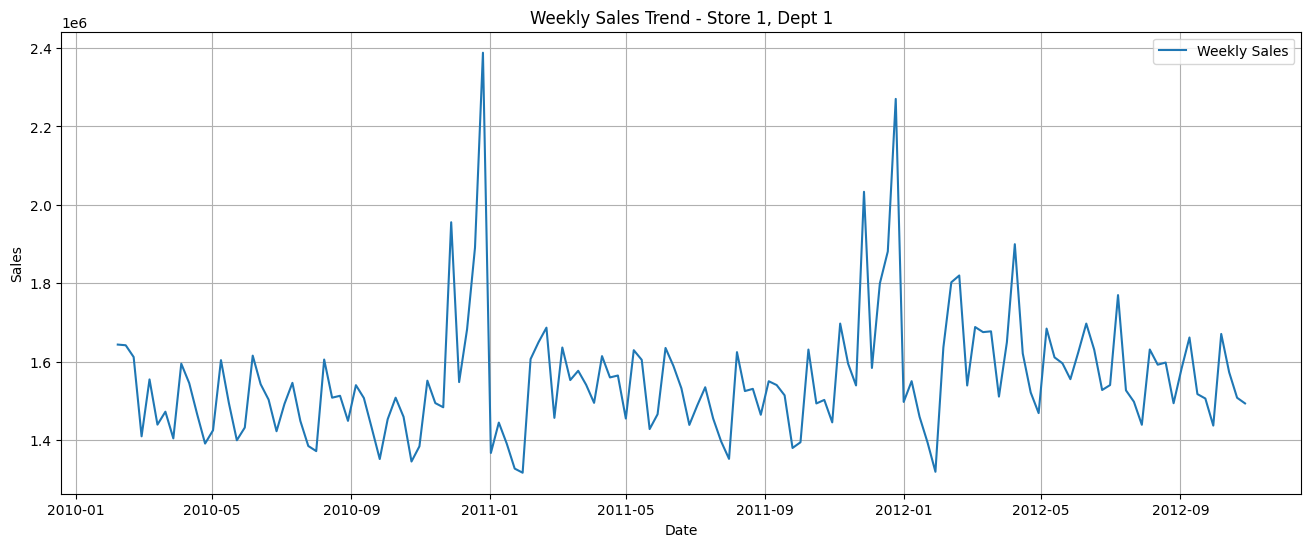

In [24]:
plt.figure(figsize=(16, 6))
plt.plot(ts_data, label='Weekly Sales')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.title('Weekly Sales Trend - Store 1, Dept 1')
plt.grid(True)
plt.legend()
plt.show()

#### Short insights from the graph:

1. Weekly sales mostly stay around 1.4M – 1.7M, showing stable demand.
2. There are large spikes (up to 2.4M) during certain weeks, likely holiday seasons like Black Friday or Christmas.
3. After these peaks, sales drop sharply, indicating a post-holiday decline.
4. The pattern repeats every year, showing strong yearly seasonality (≈52 weeks).

Summary:

Sales are generally stable but experience significant seasonal spikes during holiday periods.

## Stationarity check (ADF)

In [10]:
def check_stationarity(series):
    result = adfuller(series)
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {result[1]}')
    if result[1] <= 0.05:
        print("Series is Stationary")
    else:
        print("Series is non-Stationary, differencing required")

check_stationarity(ts_data)

ADF Statistic: -5.102186145192287
p-value: 1.3877788330759535e-05
Series is Stationary


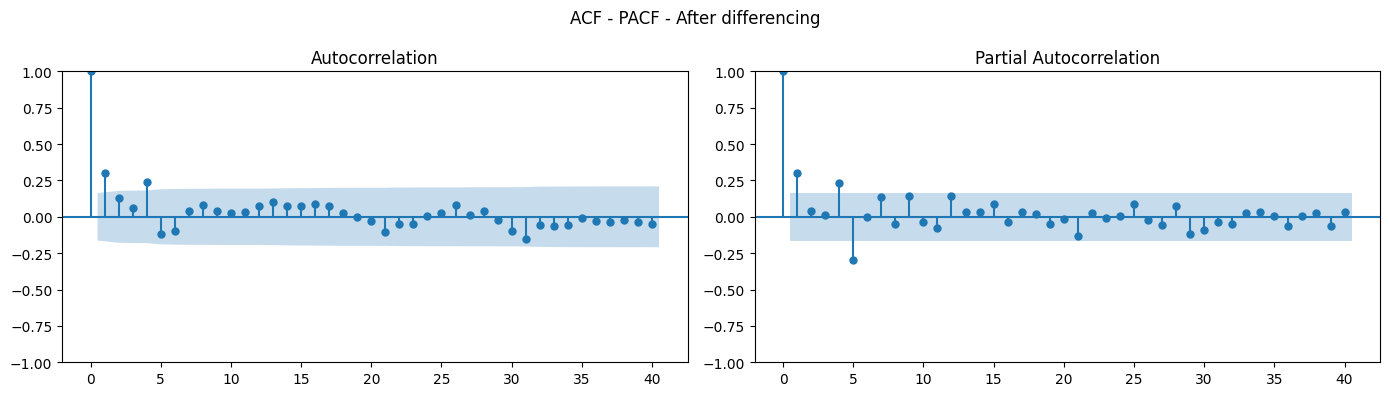

In [11]:
fig, axes = plt.subplots(1,2, figsize=(14, 4))
plot_acf(ts_data, ax=axes[0], lags=40)
plot_pacf(ts_data, ax=axes[1],lags=40)
plt.suptitle("ACF - PACF - After differencing")
plt.tight_layout()
plt.show()

In [12]:
# Train-Test Split
train_size = int(len(ts_data) * 0.8)
train_ts, test_ts = ts_data[:train_size], ts_data[train_size:]
train_exog, test_exog = exog_data[:train_size], exog_data[train_size:]
forecast_steps = len(test_ts)

## Modeling

In [13]:
train_exog = train_exog.astype(float)
test_exog = test_exog.astype(float)

# ARIMA 

In [14]:
model_arima = ARIMA(train_ts, exog=train_exog, order=(1,1,1), enforce_stationarity=False)
res_arima = model_arima.fit()
forecast_arima = res_arima.get_forecast(steps=forecast_steps, exog=test_exog).predicted_mean

# SARIMA

In [15]:
# 1. SARIMAX with Holiday 'Hint' (The Exogenous Variable)
# This prevents the flatline by telling the model when spikes should occur
model_sarimax = SARIMAX(train_ts, exog=train_exog, order=(1,1,1), 
                        seasonal_order=(1,1,1,52), enforce_stationarity=False)
res_sarimax = model_sarimax.fit(disp=False)
forecast_sarimax = res_sarimax.get_forecast(steps=forecast_steps, exog=test_exog).predicted_mean

C:\Users\Akshay12\anaconda3\envs\mynotebook\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
C:\Users\Akshay12\anaconda3\envs\mynotebook\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


# 2. Damped Exponential Smoothing

In [16]:
# 'damped_trend=True' stops the red line from shooting up to 120,000
model_es = ExponentialSmoothing(train_ts, trend='add', seasonal='add', 
                                seasonal_periods=52, damped_trend=True)
res_es = model_es.fit()
forecast_es = res_es.forecast(steps=forecast_steps)


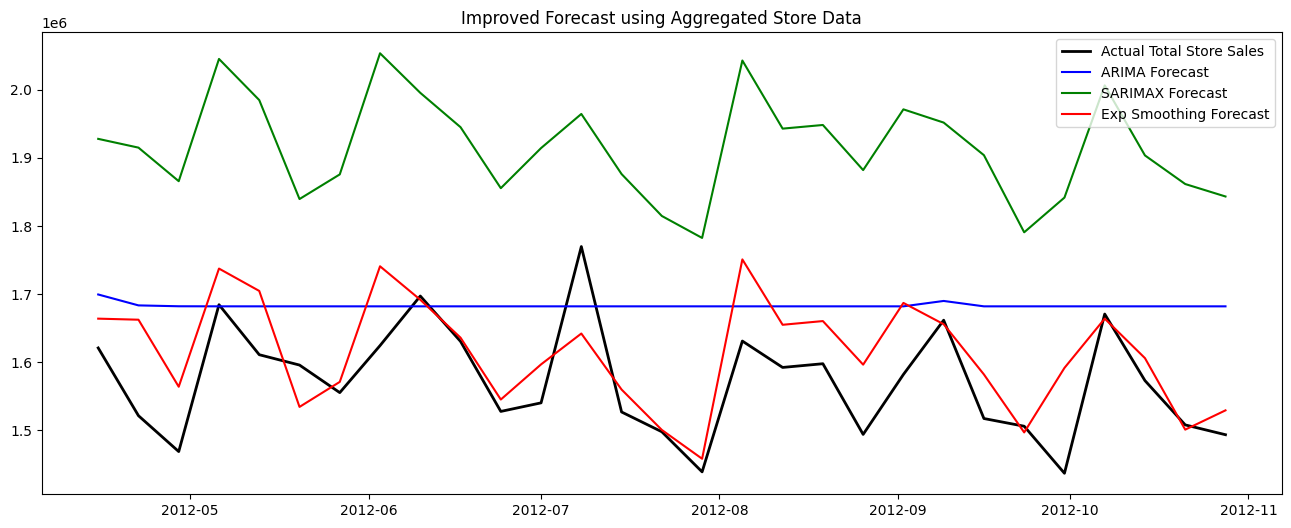

In [22]:
# Visualization
plt.figure(figsize=(16, 6))
plt.plot(test_ts.index, test_ts, label='Actual Total Store Sales', color='black', linewidth=2)
plt.plot(test_ts.index, forecast_arima, label='ARIMA Forecast', color='blue')
plt.plot(test_ts.index, forecast_sarimax, label='SARIMAX Forecast', color='green')
plt.plot(test_ts.index, forecast_es, label='Exp Smoothing Forecast', color='red')
plt.title('Improved Forecast using Aggregated Store Data')
plt.legend()
plt.show()

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate(actual, pred, name):
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    return {'Model': name, 'MAE': round(mae, 2), 'RMSE': round(rmse, 2)}

results = [
    evaluate(test_ts, forecast_arima, 'ARIMA '),
    evaluate(test_ts, forecast_sarimax, 'SARIMAX (Holiday-Aware)'),
    evaluate(test_ts, forecast_es, 'Exp Smoothing (Damped)')
]

print(pd.DataFrame(results))



                     Model        MAE       RMSE
0                   ARIMA   118602.74  136571.34
1  SARIMAX (Holiday-Aware)  343727.61  347409.78
2   Exp Smoothing (Damped)   57096.41   73251.23


##  Conclusion
The implementation of Damped Trend Exponential Smoothing is the recommended approach for this dataset. It offers the best compromise between following seasonal volatility and maintaining a realistic trend horizon. Future iterations could improve accuracy further by incorporating holiday-specific lags (e.g., "Days until Easter") to handle moving holidays more effectively.
